# Why did the July 2026 speedcheck find former CLOE faster than cloelike/cloelib?

The speedcheck notebook shared in July 2026 (`speedcheck_cloe_cloelike_firecrown_{withjax,nojax}.ipynb`, not public; see this folder's README) reports, for photometric 3x2pt on an AMD EPYC 7742:
- **CLOE 2.5x faster than cloelike/cloelib with JAX**: 0.087 s vs 0.228 s per likelihood evaluation, CAMB excluded;
- **CLOE 40x faster when JAX is "disabled"** (`JAX_DISABLE_JIT=1`): 0.086 s vs 3.75 s;
- **CLOE 17x faster for the full pipeline**, CAMB included: 0.78 s vs 13.0 s.

`time_comparison_Euclid_DR3.ipynb` and `time_comparison_Euclid_DR1.ipynb` find the opposite: cloelib 4–8x faster than former CLOE. This notebook explains the difference by re-running their exact setup on this node, and then changing one thing at a time.

**What is re-used from their tarball** (unchanged): the data files (`data/speedcheck_2026-07/inputs/`: 10-bin `niTab-EP10-RB00.dat`, `Cls_from_dat_WLPSPP.fits`, `CovMat-3x2pt-Gauss-20Bins.npz`), the parameter point, their CLOE configs (copied into CLOE's `configs/` by `environment/setup_external.sh`, new files only), their "standardized" CLOE `photo.py`, and their cloelike timing method (`Timed*` constructor wrappers, first of 21 calls discarded).

**Versions** (keys of `tp_paths.CLOELIB` / `tp_paths.CLOELIKE`, cloned by `environment/setup_external.sh`).

| | used by the speedcheck ("latest in June 2026") | today |
|---|---|---|
| cloelib | `2026-06-691c4f3` (2026-06-09) | `main-0966dfa` (2026-10-09) |
| cloelike | `2026-04-b8c8bdc` (2026-04-08); its `EuclidLikelihood_photo_Cls.py` is byte-identical to their `_original.py` | `main-2d240ea` (2026-10-06) |
| former CLOE | `tp_paths.CLOE` (archived `main`; their `photo_original.py` is identical to it) | same |

**Scripts** (each runs as a subprocess, so every cloelib version gets its own interpreter):
- `cloe_speedcheck.py` (env `cloe-former`): their CLOE config built through CLOE's own `LikelihoodUI`, their `photo.py`; cobaya's timer for one evaluation (their metric) and the median of `--repeat` direct `logp` calls, split into steps.
- `cloelike_speedcheck.py` (env `cloe-cosmosis`): their cloelike data, parameters and timing wrappers; additionally counts and times tracer construction and `get_Cl`, and profiles one call.

**CPU budget.** The notebook is run with `taskset -c 48-55` (8 CPUs, NUMA node 1 of `drontermeer`; socket 0 is throttled, see `time_comparison_Euclid_DR1.ipynb`). Section 4.1 of that notebook showed that CLOE and cloelib do not use more cores at this problem size.

> **In cloe-bench.** Executed on `drontermeer` (2026-10-09, 8 CPUs (48-55)) in a working directory outside this repository, then moved here. Since then only path handling has changed: locations come from `time_profiling/tp_paths.py`, results go to `results/` and figures to `figures/`. Local paths in the outputs are shown as `<WORKDIR>`. Set-up and re-running: `time_profiling/README.md`.


In [1]:
import json
import os
import subprocess
import time

import numpy as np
import matplotlib.pyplot as plt

import sys
HERE = os.path.abspath('.')                                   # speedcheck_reanalysis/
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))   # time_profiling/, for tp_paths
import tp_paths as tp
RES, FIGURES = os.path.join(HERE, 'results'), os.path.join(HERE, 'figures')
os.makedirs(FIGURES, exist_ok=True)   # figures are not tracked in git
PY_CLOE = str(tp.PY_CLOE_FORMER)
PY_LIB = str(tp.PY_CLOE_COSMOSIS)
tp.check(tp.CLOE, tp.PY_CLOE_FORMER, tp.PY_CLOE_COSMOSIS, tp.SPEEDCHECK)
CPUS = sorted(os.sched_getaffinity(0))
print(f'host {os.uname().nodename} | {len(CPUS)} CPUs: {CPUS[0]}-{CPUS[-1]} | load {os.getloadavg()[0]:.1f} | '
      f'OMP_NUM_THREADS={os.environ.get("OMP_NUM_THREADS", "not set")}')


def run(name, cmd, env_extra=None, cwd=HERE):
    """Run one measurement as a subprocess (inherits this kernel's CPU affinity); keep its JSON and log."""
    out = os.path.join(RES, f'{name}.json')
    env = {**os.environ, 'TMPDIR': str(tp.TMP), 'PYTHONWARNINGS': 'ignore', **(env_extra or {})}
    t0 = time.time()
    proc = subprocess.run([*cmd, '--out', out], capture_output=True, text=True, env=env, cwd=cwd)
    with open(os.path.join(RES, f'{name}.log'), 'w') as f:
        f.write(proc.stdout + proc.stderr)
    assert proc.returncode == 0, proc.stderr[-3000:]
    keep = [l for l in proc.stdout.splitlines() if l.startswith(('CLOE ', 'call ', 'median', 'profile'))]
    print(f'--- {name} ({time.time() - t0:.0f} s, load {os.getloadavg()[0]:.1f})')
    print('\n'.join(keep if len(keep) <= 6 else keep[:3] + ['   ...'] + keep[-3:]))
    with open(out) as f:
        return json.load(f)


R = {}

host drontermeer.strw.leidenuniv.nl | 8 CPUs: 48-55 | load 3.7 | OMP_NUM_THREADS=8


## 1. Their setup reproduced on this node
Both codes, exactly as in the speedcheck: photometric 3x2pt, 10 bins, 20 $\ell$ bandpowers, 210 spectra, **linear galaxy bias** (cubic polynomial in $z$) and **NLA** intrinsic alignments, Mead2020 with baryonic feedback ($\log_{10}T_{\rm AGN}=7.75$), 100 redshift points.
- **CLOE:** `IA_flag: 0`, `NL_flag_phot_bias: 0`, `NL_flag_phot_matter: 3`, `NL_flag_phot_baryon: 2`.
- **cloelike/cloelib:** `EuclidLikelihood_3x2pt`, `mode=None` (C$_\ell$ at the 20 bandpower centres, no mixing matrix), CAMB `mead2020_feedback`.

In [2]:
R['cloe'] = run('cloe_their_config', [PY_CLOE, 'cloe_speedcheck.py', '--repeat', '20'])
R['june'] = run('cloelike_june', [PY_LIB, 'cloelike_speedcheck.py', '--cloelib', '2026-06-691c4f3',
                                  '--cloelike', '2026-04-b8c8bdc', '--repeat', '21'])

--- cloe_their_config (13 s, load 4.0)
CLOE IA_flag=0 NL_flag_phot_bias=0 | cobaya Euclid timer, one evaluation: 0.0498 s | logp median of 20: 0.0416 s | steps: passing_requirements 0.0006s, update_cosmo_dic 0.0065s, loglike (C_ell + chi2) 0.0340s | chi2 6.335690e+07 | camb (excluded) {'camb.transfers': 0.2943687727674842, 'camb': 0.6434969771653414}


--- cloelike_june (134 s, load 6.7)
call  1/21: full  16.019 s | likelihood-only 10.323 s | tracers she 2x 0.419 s, pos 2x 0.306 s | get_Cl 3x 2.602 s | constructors bg/lp/nlp 3/3/3
call  2/21: full   5.478 s | likelihood-only 0.103 s | tracers she 2x 0.001 s, pos 2x 0.004 s | get_Cl 3x 0.074 s | constructors bg/lp/nlp 3/3/3
call  3/21: full   5.424 s | likelihood-only 0.103 s | tracers she 2x 0.001 s, pos 2x 0.004 s | get_Cl 3x 0.074 s | constructors bg/lp/nlp 3/3/3
   ...
call 21/21: full   5.350 s | likelihood-only 0.092 s | tracers she 2x 0.001 s, pos 2x 0.004 s | get_Cl 3x 0.074 s | constructors bg/lp/nlp 3/3/3
median of calls 2-21: full 5.457 s, likelihood-only 0.103 s
profile (self time, one call): camb 6.193s, jax/xla 0.105s, builtins/C 0.021s, numpy/scipy 0.013s, cloelib 0.007s, other python 0.004s, cloelike 0.003s, cloelib cosmology (CAMB wrappers) 0.001s


In [3]:
c, j = R['cloe'], R['june']
print(f'{"":46s} {"this node":>12s} {"speedcheck (EPYC 7742)":>24s}')
print(f'{"CLOE: cobaya timer, one evaluation [s]":46s} {c["cobaya_euclid_one_evaluation_s"]:12.3f} {0.087:24.3f}')
print(f'{"CLOE: median of 20 logp calls [s]":46s} {c["logp_median_s"]:12.3f} {"-":>24s}')
print(f'{"cloelike June: likelihood-only, median [s]":46s} {j["median"]["likelihood_only"]:12.3f} {0.228:24.3f}')
print(f'{"ratio cloelike / CLOE (cobaya timer)":46s} {j["median"]["likelihood_only"] / c["cobaya_euclid_one_evaluation_s"]:11.1f}x {2.6:23.1f}x')
print(f'\nchi2: CLOE {c["chi2"]:.6e} (speedcheck 6.33569e+07) | cloelike {-2 * j["calls"][-1]["loglike"]:.6e} '
      f'(speedcheck 6.452481e+07, CAMB)')

                                                  this node   speedcheck (EPYC 7742)
CLOE: cobaya timer, one evaluation [s]                0.050                    0.087
CLOE: median of 20 logp calls [s]                     0.042                        -
cloelike June: likelihood-only, median [s]            0.103                    0.228
ratio cloelike / CLOE (cobaya timer)                   2.1x                     2.6x

chi2: CLOE 6.335690e+07 (speedcheck 6.33569e+07) | cloelike 6.452481e+07 (speedcheck 6.452481e+07, CAMB)


**Result: their measurement reproduces.** On this node, CLOE takes 0.050 s per evaluation by cobaya's timer, and the June cloelike 0.103 s: **2.1x**, against their 2.6x. Both χ² values match theirs to all printed digits. This node is about 2x faster than their EPYC 7742 for both codes. So the speedcheck is not wrong for the case it measured. The question is what that case represents.

## 2. What is inside cloelike's "likelihood-only" time?
The speedcheck's metric is the full `loglike` call minus the constructor time of `Background`, `LinPerturbations` and `NonLinPerturbations`. What remains is cloelib's tracers, kernels and Limber integrals, plus the $\chi^2$. The script times the pieces inside it, and profiles one call.

In [4]:
def breakdown(r):
    m = r['median']
    rest = m['likelihood_only'] - m['get_Cl_s'] - m['she_tracer_s'] - m['pos_tracer_s']
    return m, rest


m, rest = breakdown(R['june'])
print(f'cloelike June, median of calls 2-21 [s]: likelihood-only {m["likelihood_only"]:.3f} = '
      f'get_Cl x{m["get_Cl_n"]:.0f} {m["get_Cl_s"]:.3f} + ShearTracer x{m["she_tracer_n"]:.0f} {m["she_tracer_s"]:.3f} + '
      f'PositionsTracer x{m["pos_tracer_n"]:.0f} {m["pos_tracer_s"]:.3f} + rest (data vector, chi2, glue) {rest:.3f}')
print(f'  constructors per call (subtracted): Background x{m["bg_n"]:.0f}, LinPerturbations x{m["lp_n"]:.0f}, '
      f'NonLinPerturbations x{m["nlp_n"]:.0f} = {m["bg_s"] + m["lp_s"] + m["nlp_s"]:.2f} s')
print(f'  first call (JAX compilation): likelihood-only {R["june"]["calls"][0]["likelihood_only"]:.2f} s')
cs = R['cloe']['steps_median_s']
print(f'\nCLOE, median of 20 [s]: ' + ', '.join(f'{k} {v:.4f}' for k, v in cs.items()))

top = R['june']['profile_top']
n_dispatch = sum(r[1] for r in top if 'dispatch.py' in r[0] and 'apply_primitive' in r[0])
print(f'\nProfile of one cloelike June call: {n_dispatch} eager JAX primitive dispatches (jax/_src/dispatch.py:apply_primitive)')
for r in top[:12]:
    print(f'  {r[1]:7d} calls  self {r[2]:7.4f} s  cum {r[3]:7.4f} s  {r[0].split("site-packages/")[-1]}')

cloelike June, median of calls 2-21 [s]: likelihood-only 0.103 = get_Cl x3 0.074 + ShearTracer x2 0.001 + PositionsTracer x2 0.004 + rest (data vector, chi2, glue) 0.024
  constructors per call (subtracted): Background x3, LinPerturbations x3, NonLinPerturbations x3 = 5.34 s
  first call (JAX compilation): likelihood-only 10.32 s

CLOE, median of 20 [s]: passing_requirements 0.0006, update_cosmo_dic 0.0065, loglike (C_ell + chi2) 0.0340

Profile of one cloelike June call: 1626 eager JAX primitive dispatches (jax/_src/dispatch.py:apply_primitive)
        6 calls  self  4.6643 s  cum  4.6644 s  camb/results.py:339(calc_transfers)
       15 calls  self  1.4706 s  cum  1.4716 s  camb/results.py:804(get_linear_matter_power_spectrum)
        3 calls  self  0.0553 s  cum  0.0553 s  camb/results.py:328(calc_background)
     1626 calls  self  0.0235 s  cum  0.0246 s  jax/_src/dispatch.py:81(apply_primitive)
        9 calls  self  0.0084 s  cum  0.0086 s  scipy/interpolate/_fitpack2.py:1620(__in

**Result: at this problem size, cloelib's time is mostly JAX dispatch overhead, not arithmetic.**
- Of cloelike's 0.103 s, 0.074 s is the three `get_Cl` calls. Building the four tracers takes 0.005 s, and the rest (data vector, χ², Python glue) about 0.024 s.
- One call makes **1,626 eager JAX primitive dispatches**: operations outside any `jax.jit`, each sent to XLA separately. There are also 1,150 dtype conversions and about 400 static slices. The profiler attributes about 0.05 s of cumulative time to dispatching alone. The actual arithmetic (10 bins × 20 ℓ × 100 redshifts) takes microseconds.
- CLOE does the same physics in NumPy/SciPy: `update_cosmo_dic` 7 ms (no FAST-PT in this model) and C_ℓ + χ² 34 ms.
- cloelib is built to amortise a fixed per-operation cost over large, batched arrays (many bins, many ℓ, perturbation-theory terms). Here the arrays are tiny, so that fixed cost dominates.
- The first call (JAX compilation) costs 10 s. The speedcheck correctly discards it.

## 3. "JAX disabled" is `JAX_DISABLE_JIT=1`
The speedcheck's no-JAX run sets `JAX_DISABLE_JIT=1`. That does not switch cloelib to NumPy. It keeps every JAX operation, but runs the functions that are normally compiled (`jax.jit`) one primitive at a time, each with its Python dispatch overhead. It is a debugging mode, not a production configuration.

In [5]:
R['june_nojit'] = run('cloelike_june_nojit', [PY_LIB, 'cloelike_speedcheck.py', '--cloelib', '2026-06-691c4f3',
                                              '--cloelike', '2026-04-b8c8bdc', '--repeat', '6'],
                      env_extra={'JAX_DISABLE_JIT': '1'})
mj, mn = R['june']['median'], R['june_nojit']['median']
print(f'\nlikelihood-only: JIT {mj["likelihood_only"]:.3f} s, JAX_DISABLE_JIT=1 {mn["likelihood_only"]:.3f} s '
      f'({mn["likelihood_only"] / mj["likelihood_only"]:.0f}x) | vs CLOE: '
      f'{mn["likelihood_only"] / R["cloe"]["cobaya_euclid_one_evaluation_s"]:.0f}x (speedcheck: 43x)')

--- cloelike_june_nojit (79 s, load 3.7)
call  1/6: full  26.869 s | likelihood-only 21.468 s | tracers she 2x 2.000 s, pos 2x 1.462 s | get_Cl 3x 14.040 s | constructors bg/lp/nlp 3/3/3
call  2/6: full   7.559 s | likelihood-only 2.261 s | tracers she 2x 0.920 s, pos 2x 0.926 s | get_Cl 3x 0.390 s | constructors bg/lp/nlp 3/3/3
call  3/6: full   7.743 s | likelihood-only 2.257 s | tracers she 2x 0.920 s, pos 2x 0.925 s | get_Cl 3x 0.388 s | constructors bg/lp/nlp 3/3/3
   ...
call  6/6: full   7.637 s | likelihood-only 2.280 s | tracers she 2x 0.919 s, pos 2x 0.924 s | get_Cl 3x 0.397 s | constructors bg/lp/nlp 3/3/3
median of calls 2-6: full 7.637 s, likelihood-only 2.280 s
profile (self time, one call): camb 5.369s, jax/xla 4.227s, builtins/C 0.774s, numpy/scipy 0.111s, other python 0.108s, cloelike 0.015s, cloelib 0.006s, cloelib cosmology (CAMB wrappers) 0.000s

likelihood-only: JIT 0.103 s, JAX_DISABLE_JIT=1 2.280 s (22x) | vs CLOE: 46x (speedcheck: 43x)


**Result: the 40x is a debugging mode, not "cloelib without JAX".** With `JAX_DISABLE_JIT=1` the same cloelike takes 2.28 s, 22x its normal time and 46x CLOE (their 43x).
- Building each tracer goes from 1 ms to 0.9 s, because the compiled interpolation and kernel functions now run one primitive at a time.
- No real analysis would run cloelib this way. There is no NumPy fallback being measured here.

## 4. cloelike/cloelib today
Since the speedcheck, cloelike gh-159 (`186fd1b`, 2026-09-09, *caching kernels to avoid duplicate time*) builds `Background`, the perturbations and each tracer once per likelihood call; the June version rebuilt them for every probe (3x for 3x2pt). cloelib has also moved on four months.

The current cloelike also **caches** these objects per cosmology. Calling `loglike` repeatedly at one fixed point, as the speedcheck does, would then time cache hits. `--clear-cache` empties the caches before every call, so each call is a full evaluation, as at a new point of a chain. The run without it shows what the speedcheck's method would report today.

In [6]:
R['main'] = run('cloelike_main', [PY_LIB, 'cloelike_speedcheck.py', '--cloelib', 'main-0966dfa',
                                  '--cloelike', 'main-2d240ea', '--repeat', '21', '--clear-cache'])
R['main_cached'] = run('cloelike_main_fixed_point', [PY_LIB, 'cloelike_speedcheck.py', '--cloelib', 'main-0966dfa',
                                                     '--cloelike', 'main-2d240ea', '--repeat', '21'])
for key, label in (('june', 'June 2026'), ('main', 'today, caches cleared'), ('main_cached', 'today, fixed point (cache hits)')):
    m, rest = breakdown(R[key])
    print(f'{label:32s} likelihood-only {m["likelihood_only"]:.3f} s | get_Cl x{m["get_Cl_n"]:.0f} {m["get_Cl_s"]:.3f} s | '
          f'tracers {m["she_tracer_n"] + m["pos_tracer_n"]:.0f} | constructors {m["bg_n"]:.0f}+{m["lp_n"]:.0f}+{m["nlp_n"]:.0f} '
          f'= {m["bg_s"] + m["lp_s"] + m["nlp_s"]:.2f} s | full call {m["full"]:.2f} s')

--- cloelike_main (60 s, load 6.3)
call  1/21: full  13.382 s | likelihood-only 11.581 s | tracers she 1x 0.414 s, pos 1x 0.301 s | get_Cl 3x 1.298 s | constructors bg/lp/nlp 1/1/1
call  2/21: full   1.919 s | likelihood-only 0.092 s | tracers she 1x 0.001 s, pos 1x 0.002 s | get_Cl 3x 0.065 s | constructors bg/lp/nlp 1/1/1
call  3/21: full   4.930 s | likelihood-only 0.087 s | tracers she 1x 0.001 s, pos 1x 0.002 s | get_Cl 3x 0.062 s | constructors bg/lp/nlp 1/1/1
   ...
call 21/21: full   1.924 s | likelihood-only 0.087 s | tracers she 1x 0.001 s, pos 1x 0.002 s | get_Cl 3x 0.061 s | constructors bg/lp/nlp 1/1/1
median of calls 2-21: full 1.925 s, likelihood-only 0.086 s
profile (self time, one call): camb 1.842s, jax/xla 0.099s, builtins/C 0.020s, cloelike 0.014s, numpy/scipy 0.006s, cloelib 0.004s, other python 0.004s, cloelib cosmology (CAMB wrappers) 0.000s


--- cloelike_main_fixed_point (18 s, load 6.5)
call  1/21: full  11.363 s | likelihood-only 9.520 s | tracers she 1x 0.433 s, pos 1x 0.299 s | get_Cl 3x 1.349 s | constructors bg/lp/nlp 1/1/1
call  2/21: full   0.241 s | likelihood-only 0.241 s | tracers she 0x 0.000 s, pos 0x 0.000 s | get_Cl 3x 0.227 s | constructors bg/lp/nlp 0/0/0
call  3/21: full   0.215 s | likelihood-only 0.215 s | tracers she 0x 0.000 s, pos 0x 0.000 s | get_Cl 3x 0.203 s | constructors bg/lp/nlp 0/0/0
   ...
call 21/21: full   0.198 s | likelihood-only 0.198 s | tracers she 0x 0.000 s, pos 0x 0.000 s | get_Cl 3x 0.149 s | constructors bg/lp/nlp 0/0/0
median of calls 2-21: full 0.196 s, likelihood-only 0.196 s
profile (self time, one call): jax/xla 0.097s, camb 0.086s, builtins/C 0.019s, cloelike 0.014s, numpy/scipy 0.006s, other python 0.003s, cloelib 0.003s, cloelib cosmology (CAMB wrappers) 0.000s
June 2026                        likelihood-only 0.103 s | get_Cl x3 0.074 s | tracers 4 | constructors 3+3+3 = 

**Result: cloelike today is faster, but still about 1.7–2x slower than CLOE for this model.**
- With caches cleared before each call, every call is a real new point. The likelihood-only time is 0.086 s (June: 0.103 s). Since gh-159 there are 2 tracers per call instead of 4, and one Background/perturbations set instead of three.
- `get_Cl` is still called three times: one Limber call per probe (WL, GGL, GCph). It costs 0.061 s, and the eager-dispatch overhead of section 2 remains.
- **Pitfall in re-running the speedcheck today.** At a fixed point, the current cloelike reuses its cached perturbations and tracers, so the constructors are never called (0/0/0). Yet the likelihood-only time *rises* to 0.196 s, because `get_Cl` takes 0.17 s instead of 0.06 s on cached tracers. That is unexpected and worth reporting to cloelib; it was not investigated further here. Either way, a fixed-point repeat is not a valid timing method for the current cloelike: it either times cache hits or this slow path.

## 5. The model decides who wins
The speedcheck's model has no perturbation-theory terms, so CLOE never calls FAST-PT. In `time_comparison_Euclid_DR3/DR1.ipynb` the model is TATT + one-loop galaxy bias, where CLOE spends 1.2 s per evaluation in `update_cosmo_dic` rebuilding FAST-PT objects. The same CLOE configuration, with only `IA_flag = 1` (TATT) and `NL_flag_phot_bias = 1` (one-loop bias) switched on. FAST-PT needs an even number of $k$ points, so `k_samp` goes from 209 to 210. That is the smallest possible change and a conservative one: CLOE's default, 1000 points (used in the DR1/DR3 notebooks), would make CLOE slower still.

In [7]:
R['cloe_tatt_nl'] = run('cloe_tatt_nlbias', [PY_CLOE, 'cloe_speedcheck.py', '--repeat', '10', '--ia-flag', '1',
                                             '--nl-bias', '1', '--k-samp', '210'])
for key, label in (('cloe', 'linear bias + NLA (speedcheck)'), ('cloe_tatt_nl', 'one-loop bias + TATT')):
    c = R[key]
    print(f'CLOE {label:32s} one evaluation {c["cobaya_euclid_one_evaluation_s"]:.3f} s | median {c["logp_median_s"]:.3f} s | '
          + ', '.join(f'{k} {v:.3f}' for k, v in c['steps_median_s'].items()))
dr1 = {}
for n in (8, 96):
    fn = os.path.join(tp.STUDIES, 'euclid_dr1', 'results', f'timings_Euclid_DR1_{n}cpu.json')
    if os.path.exists(fn):
        with open(fn) as f:
            dr1[n] = json.load(f)['results']
if dr1:
    r = dr1[min(dr1)]
    print(f'\nFor reference, time_comparison_Euclid_DR1.ipynb ({min(dr1)} CPUs, 6 bins, TATT + one-loop bias, n_ell = 32): '
          f'cloelib {r["cloelib"]["32"]:.2f} s, former CLOE {r["CLOE (former)"]["32"]:.2f} s')

--- cloe_tatt_nlbias (21 s, load 5.6)
CLOE IA_flag=1 NL_flag_phot_bias=1 | cobaya Euclid timer, one evaluation: 0.4343 s | logp median of 10: 0.4262 s | steps: passing_requirements 0.0114s, update_cosmo_dic 0.3796s, loglike (C_ell + chi2) 0.0341s | chi2 2.264903e+08 | camb (excluded) {'camb.transfers': 0.21421867795288563, 'camb': 0.5985936084762216}
CLOE linear bias + NLA (speedcheck)   one evaluation 0.050 s | median 0.042 s | passing_requirements 0.001, update_cosmo_dic 0.007, loglike (C_ell + chi2) 0.034
CLOE one-loop bias + TATT             one evaluation 0.434 s | median 0.426 s | passing_requirements 0.011, update_cosmo_dic 0.380, loglike (C_ell + chi2) 0.034

For reference, time_comparison_Euclid_DR1.ipynb (8 CPUs, 6 bins, TATT + one-loop bias, n_ell = 32): cloelib 0.16 s, former CLOE 1.20 s


**Result: switching on the perturbation-theory terms reverses the picture.**
- With TATT + one-loop bias, CLOE's `update_cosmo_dic` goes from 7 ms to 0.38 s, because it rebuilds its FAST-PT objects on every evaluation. One evaluation then takes 0.43 s, 9x its linear-model time. That is with only 210 $k$ points; with CLOE's default 1000 it is 1.2 s (DR1/DR3 notebooks).
- In `time_comparison_Euclid_DR1.ipynb`, with the same model class, cloelib takes 0.16 s per evaluation against CLOE's 1.20 s.
- The two results are therefore consistent. For a linear-bias + NLA 3x2pt, CLOE's lightweight NumPy path wins by about 2x. For the models in the Euclid baseline with PT terms, cloelib's batched FAST-PT + JAX path wins by about 7x.
- Caveat: the June cloelike hard-codes polynomial linear bias and NLA, so cloelike with TATT + one-loop bias was not run on the speedcheck data. The cloelib number comes from the DR1 notebook (6 bins, its own data).

## 6. The full pipeline: 17x is CAMB inside cloelib
The speedcheck's full-pipeline ratio (0.78 s vs 13 s) includes CAMB. For CLOE, CAMB runs through cobaya; for cloelike/cloelib, through `CAMBLinearPerturbations` and `CAMBNonLinearPerturbations`.

In [8]:
c = R['cloe']
print('CLOE, cobaya CAMB per evaluation [s]: ' + ', '.join(f'{k} {v:.2f}' for k, v in c['cobaya_theory_s'].items()))
for key, label in (('june', 'June 2026'), ('main', 'today')):
    m = R[key]['median']
    print(f'cloelike {label:10s}: Background x{m["bg_n"]:.0f} {m["bg_s"]:.2f} s, LinPerturbations x{m["lp_n"]:.0f} '
          f'{m["lp_s"]:.2f} s, NonLinPerturbations x{m["nlp_n"]:.0f} {m["nlp_s"]:.2f} s  -> full call {m["full"]:.2f} s')

CLOE, cobaya CAMB per evaluation [s]: camb.transfers 0.29, camb 0.64
cloelike June 2026 : Background x3 0.08 s, LinPerturbations x3 1.49 s, NonLinPerturbations x3 3.78 s  -> full call 5.46 s
cloelike today     : Background x1 0.08 s, LinPerturbations x1 0.51 s, NonLinPerturbations x1 1.26 s  -> full call 1.93 s


**Result: the 17x full-pipeline ratio was cloelib's CAMB set-up, run three times.**
- June cloelike, per evaluation: 3 × (`CAMBLinearPerturbations` + `CAMBNonLinearPerturbations`) = 5.3 s on this node (their 13 s).
- CLOE, through cobaya: 0.93 s (`camb.transfers` 0.29 + `camb` 0.64).
- Today cloelike runs CAMB once, at 1.85 s per evaluation. The full-pipeline ratio drops to about 2x.
- The remaining factor is that cloelib runs two separate CAMB calculations, a linear one to kmax = 300 and a non-linear one to kmax = 500, where cobaya runs one transfer calculation. That is worth an issue on cloelib, since in a chain CAMB dominates every likelihood evaluation.

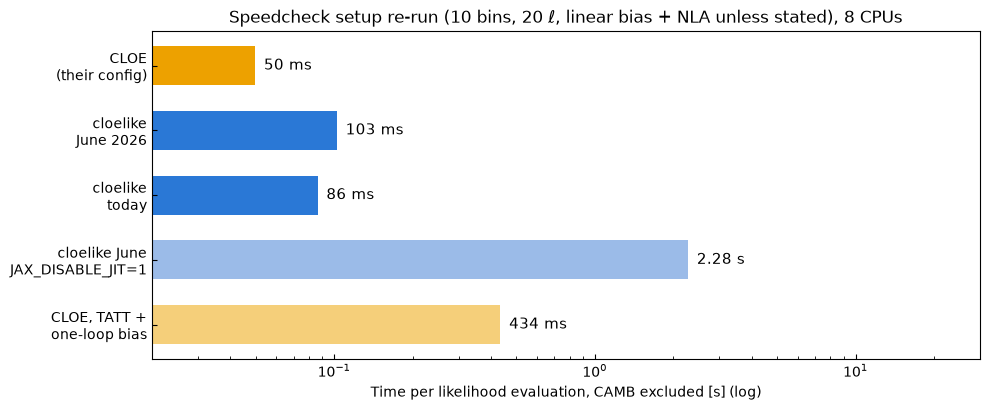

In [9]:
rows = [('CLOE\n(their config)', R['cloe']['cobaya_euclid_one_evaluation_s'], '#eda100'),
        ('cloelike\nJune 2026', R['june']['median']['likelihood_only'], '#2a78d6'),
        ('cloelike\ntoday', R['main']['median']['likelihood_only'], '#2a78d6'),
        ('cloelike June\nJAX_DISABLE_JIT=1', R['june_nojit']['median']['likelihood_only'], '#9bbbe8'),
        ('CLOE, TATT +\none-loop bias', R['cloe_tatt_nl']['cobaya_euclid_one_evaluation_s'], '#f5cf7a')]
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(rows))[::-1]
ax.barh(y, [r[1] for r in rows], color=[r[2] for r in rows], height=0.6)
for yi, (lab, v, _) in zip(y, rows):
    ax.text(v * 1.08, yi, f'{v * 1e3:.0f} ms' if v < 1 else f'{v:.2f} s', va='center', fontsize=11)
ax.set_yticks(y)
ax.set_yticklabels([r[0] for r in rows], fontsize=10)
ax.set_xscale('log')
ax.set_xlim(0.02, 30)
ax.set_xlabel('Time per likelihood evaluation, CAMB excluded [s] (log)')
ax.set_title('Speedcheck setup re-run (10 bins, 20 $\\ell$, linear bias + NLA unless stated), '
             f'{len(CPUS)} CPUs', fontsize=12)
ax.tick_params(axis='both', which='both', direction='in')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES, 'speedcheck_reanalysis.png'), dpi=150, bbox_inches='tight')
plt.show()

## 7. Summary
**Why the speedcheck found former CLOE faster.** Its measurements are reproducible (2.1x here, 2.6x there), and they are correct for the case it timed. That case is the one where cloelib is weakest:
1. **A model without perturbation-theory terms.** With linear bias + NLA, CLOE never runs FAST-PT, and its evaluation is 40 ms of NumPy. With TATT + one-loop bias, CLOE's FAST-PT rebuild takes over (0.4–1.2 s) and cloelib is about 7x faster (DR1/DR3 notebooks).
2. **A very small problem**: 10 bins × 20 ℓ × 100 redshifts. cloelib's cost is then dominated by about 1,600 eager JAX dispatches per evaluation, not by computation.
3. **A June-2026 cloelike that rebuilt everything for each probe.** It made 3 CAMB set-ups and 4 tracers per call; fixed in gh-159 (September 2026). This mostly inflated the full-pipeline ratio (17x → about 2x today) and slightly inflated the likelihood-only time (0.103 → 0.086 s).
4. **"No JAX" meant `JAX_DISABLE_JIT=1`**, a debugging mode that dispatches every compiled function primitive by primitive (22x slower). It does not represent cloelib without JAX, so the 40x should not be quoted.

**What is genuinely worth acting on in cloelib/cloelike:**
- For small linear-model problems, cloelib loses about 2x to plain NumPy because of eager JAX dispatch. Jitting the tracer → kernel → Limber path end to end, or batching the three probes into one `get_Cl`, would remove most of it.
- cloelib runs two CAMB calculations per cosmology (linear kmax 300 and non-linear kmax 500), about 2x cobaya's single call.
- With the current cloelike, `get_Cl` on cached tracers is about 3x slower than on fresh ones (section 4).

**For the thread:** quote the comparison per model. Linear bias + NLA: CLOE about 2x faster. TATT + one-loop bias: cloelib about 7x faster. Report JIT-enabled timings only, and re-run with the current cloelike, clearing its caches or varying the parameters between calls.